In [1]:

# ==========================================
# NOTEBOOK 03 - ANÁLISIS TEMPORAL Y SOLAR
# 1. AUDITORÍA DE COLUMNAS TEMPORALES
# ==========================================

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Ubicar los CSV originales
DATASET_DIR = Path("../dataset")

if not DATASET_DIR.exists():
    DATASET_DIR = Path("dataset")

archivos = sorted(
    DATASET_DIR.glob("forecast_observation_*.csv")
)

# Excluir fechas identificadas en la auditoría
fechas_excluidas = {
    f"2026_10_{dia:02d}"
    for dia in range(22, 27)
}

archivos_analisis = [
    archivo for archivo in archivos
    if archivo.stem.replace(
        "forecast_observation_", ""
    ) not in fechas_excluidas
]

print("Archivos originales:", len(archivos))
print("Archivos seleccionados:", len(archivos_analisis))

if len(archivos_analisis) != 48:
    raise ValueError(
        "Se esperaban 48 archivos seleccionados. "
        "Revisar la ruta y las exclusiones."
    )

# Leer únicamente una muestra para revisar el esquema
muestra = pd.read_csv(
    archivos_analisis[0],
    nrows=5
)

# Identificar columnas relacionadas con fechas y horas
terminos_temporales = (
    "time", "date", "utc", "timezone",
    "hour", "solar", "offset"
)

columnas_temporales = [
    columna
    for columna in muestra.columns
    if any(
        termino in columna.lower()
        for termino in terminos_temporales
    )
]

print("\nCOLUMNAS TEMPORALES IDENTIFICADAS:")
for columna in columnas_temporales:
    print("-", columna)

print("\nEJEMPLOS DE VALORES:")
display(
    muestra[columnas_temporales].T
)

print("\nTIPOS DE DATOS INFERIDOS EN LA MUESTRA:")
display(
    muestra[columnas_temporales].dtypes
)


Archivos originales: 53
Archivos seleccionados: 48

COLUMNAS TEMPORALES IDENTIFICADAS:
- snapshot_time_utc
- collection_time_utc
- forecast_generated_at_utc
- forecast_update_time_utc
- horizon_target_hours
- source_horizon_target_hours
- target_time_utc
- source_target_time_utc
- forecast_start_utc
- forecast_end_utc
- actual_lead_hours
- source_actual_lead_hours
- observation_time_difference_minutes
- observation_time_utc
- observation_collection_hour_utc

EJEMPLOS DE VALORES:


,0,1,2,3,4
snapshot_time_utc,2026-09-08T00:00:00+00:00,2026-09-08T00:00:00+00:00,2026-09-08T00:00:00+00:00,2026-09-08T00:00:00+00:00,2026-09-08T00:00:00+00:00
collection_time_utc,2026-09-08T00:15:05.950794+00:00,2026-09-08T00:15:05.950794+00:00,2026-09-08T00:15:05.950794+00:00,2026-09-08T00:15:05.950794+00:00,2026-09-08T00:15:05.950794+00:00
forecast_generated_at_utc,2026-09-08T00:00:20+00:00,2026-09-08T00:15:16+00:00,2026-09-08T00:15:06+00:00,2026-09-07T23:54:11+00:00,2026-09-08T00:15:43+00:00
forecast_update_time_utc,2026-09-07T19:41:51+00:00,2026-09-07T20:16:33+00:00,2026-09-07T20:01:12+00:00,2026-09-07T20:52:45+00:00,2026-09-07T20:09:50+00:00
horizon_target_hours,48,48,48,48,48
source_horizon_target_hours,48.0,48.0,48.0,48.0,48.0
target_time_utc,2026-09-10T00:00:00+00:00,2026-09-10T00:00:00+00:00,2026-09-10T00:00:00+00:00,2026-09-10T00:00:00+00:00,2026-09-10T00:00:00+00:00
source_target_time_utc,2026-09-10T00:00:20+00:00,2026-09-10T00:15:16+00:00,2026-09-10T00:15:06+00:00,2026-09-09T23:54:11+00:00,2026-09-10T00:15:43+00:00
forecast_start_utc,2026-09-10T00:00:00+00:00,2026-09-10T00:00:00+00:00,2026-09-10T00:00:00+00:00,2026-09-10T00:00:00+00:00,2026-09-10T00:00:00+00:00
forecast_end_utc,2026-09-10T01:00:00+00:00,2026-09-10T01:00:00+00:00,2026-09-10T01:00:00+00:00,2026-09-10T01:00:00+00:00,2026-09-10T01:00:00+00:00



TIPOS DE DATOS INFERIDOS EN LA MUESTRA:


snapshot_time_utc                          str
collection_time_utc                        str
forecast_generated_at_utc                  str
forecast_update_time_utc                   str
horizon_target_hours                     int64
source_horizon_target_hours            float64
target_time_utc                            str
source_target_time_utc                     str
forecast_start_utc                         str
forecast_end_utc                           str
actual_lead_hours                      float64
source_actual_lead_hours               float64
observation_time_difference_minutes    float64
observation_time_utc                       str
observation_collection_hour_utc            str
dtype: object

Interpretación de las columnas temporales
| Columna |	Qué representa |
|---------|----------------|
| snapshot_time_utc |	Momento de referencia de la captura del pronóstico |
| collection_time_utc |	Momento en que se realizó la recolección |
| forecast_generated_at_utc |	Marca temporal de generación informada por la fuente |
| forecast_update_time_utc |	Marca de actualización informada por la fuente |
| target_time_utc |	Momento objetivo del pronóstico |
| forecast_start_utc |	Comienzo del intervalo pronosticado |
| forecast_end_utc |	Final del intervalo pronosticado |
| observation_time_utc |	Momento de la observación real |
| observation_collection_hour_utc |	Hora de referencia de recolección de la observación |
| horizon_target_hours |	Horizonte nominal desde el snapshot hasta el objetivo |
| source_actual_lead_hours |	Anticipación temporal informada por la fuente |


In [2]:

# ==========================================
# 2. VERIFICACIÓN TEMPORAL - HORIZONTES 12 Y 24 H
# ==========================================

columnas = [
    "horizon_target_hours",
    "match_type",
    "snapshot_time_utc",
    "collection_time_utc",
    "forecast_generated_at_utc",
    "target_time_utc",
    "forecast_start_utc",
    "forecast_end_utc",
    "observation_time_utc",
    "temperature_forecast_c",
    "temperature_observed_c"
]

fragmentos = []

# Leer el primer archivo por bloques
for bloque in pd.read_csv(
    archivos_analisis[0],
    usecols=columnas,
    chunksize=100_000
):

    filtro = (
        bloque["horizon_target_hours"].isin([12, 24])
        & bloque["match_type"].eq("interval")
        & bloque["temperature_forecast_c"].notna()
        & bloque["temperature_observed_c"].notna()
    )

    seleccion = bloque.loc[filtro].copy()

    if not seleccion.empty:
        fragmentos.append(seleccion)

if not fragmentos:
    raise ValueError(
        "No se encontraron registros válidos de 12 o 24 horas."
    )

df_tiempo_muestra = pd.concat(
    fragmentos,
    ignore_index=True
)

# Convertir fechas a formato datetime UTC
columnas_fecha = [
    "snapshot_time_utc",
    "collection_time_utc",
    "forecast_generated_at_utc",
    "target_time_utc",
    "forecast_start_utc",
    "forecast_end_utc",
    "observation_time_utc"
]

for columna in columnas_fecha:
    df_tiempo_muestra[columna] = pd.to_datetime(
        df_tiempo_muestra[columna],
        utc=True,
        errors="coerce"
    )

# Diferencia entre objetivo y snapshot
df_tiempo_muestra["horizonte_calculado_h"] = (
    df_tiempo_muestra["target_time_utc"]
    - df_tiempo_muestra["snapshot_time_utc"]
).dt.total_seconds() / 3600

# Diferencia entre comienzo del intervalo y objetivo
df_tiempo_muestra["inicio_vs_objetivo_min"] = (
    df_tiempo_muestra["forecast_start_utc"]
    - df_tiempo_muestra["target_time_utc"]
).dt.total_seconds() / 60

# Minutos desde el comienzo del intervalo hasta la observación
df_tiempo_muestra["observacion_desde_inicio_min"] = (
    df_tiempo_muestra["observation_time_utc"]
    - df_tiempo_muestra["forecast_start_utc"]
).dt.total_seconds() / 60

# Resumen
print("REGISTROS POR HORIZONTE:")
display(
    df_tiempo_muestra[
        "horizon_target_hours"
    ].value_counts().sort_index()
)

print("\nCONSISTENCIA DE LOS TIEMPOS:")
display(
    df_tiempo_muestra.groupby(
        "horizon_target_hours"
    )[
        [
            "horizonte_calculado_h",
            "inicio_vs_objetivo_min",
            "observacion_desde_inicio_min"
        ]
    ].agg(["min", "median", "max"]).round(2)
)

print("\nEJEMPLOS DE FECHAS POR HORIZONTE:")
display(
    df_tiempo_muestra.groupby(
        "horizon_target_hours"
    ).head(2)[
        [
            "horizon_target_hours",
            "snapshot_time_utc",
            "forecast_generated_at_utc",
            "target_time_utc",
            "forecast_start_utc",
            "forecast_end_utc",
            "observation_time_utc"
        ]
    ]
)


REGISTROS POR HORIZONTE:


horizon_target_hours
12    8311
24    8311
Name: count, dtype: int64


CONSISTENCIA DE LOS TIEMPOS:


horizonte_calculado_h               \
                                       min median   max   
horizon_target_hours                                      
12                                    12.0   12.0  12.0   
24                                    24.0   24.0  24.0   

                     inicio_vs_objetivo_min              \
                                        min median  max   
horizon_target_hours                                      
12                                      0.0    0.0  0.0   
24                                      0.0    0.0  0.0   

                     observacion_desde_inicio_min               
                                              min median   max  
horizon_target_hours                                            
12                                            0.0   40.0  59.0  
24                                            0.0   40.0  59.0


EJEMPLOS DE FECHAS POR HORIZONTE:


,horizon_target_hours,snapshot_time_utc,forecast_generated_at_utc,target_time_utc,forecast_start_utc,forecast_end_utc,observation_time_utc
0,24,2026-09-09 00:00:00+00:00,2026-09-09 00:19:03+00:00,2026-09-10 00:00:00+00:00,2026-09-10 00:00:00+00:00,2026-09-10 01:00:00+00:00,2026-09-10 00:45:00+00:00
1,24,2026-09-09 00:00:00+00:00,2026-09-09 00:00:35+00:00,2026-09-10 00:00:00+00:00,2026-09-10 00:00:00+00:00,2026-09-10 01:00:00+00:00,2026-09-10 00:40:00+00:00
4453,12,2026-09-09 12:00:00+00:00,2026-09-09 12:16:46+00:00,2026-09-10 00:00:00+00:00,2026-09-10 00:00:00+00:00,2026-09-10 01:00:00+00:00,2026-09-10 00:45:00+00:00
4455,12,2026-09-09 12:00:00+00:00,2026-09-09 12:15:54+00:00,2026-09-10 00:00:00+00:00,2026-09-10 00:00:00+00:00,2026-09-10 01:00:00+00:00,2026-09-10 00:40:00+00:00


Interpretación de la consistencia temporal

| Verificación |	12 horas |	24 horas |	Resultado |
|--------------|-------------|-----------|------------|
| Horizonte calculado |	12 h |	24 h |	Coincide |
| Inicio del intervalo vs. objetivo |	0 min |	0 min |	Coincide |
| Observación respecto del inicio |	0–59 min |	0–59 min |	Dentro del intervalo |
| Mediana del momento de observación |	40 min |	40 min |	Igual en ambos horizontes |

Esto confirma que, en el archivo examinado:
1. horizon_target_hours corresponde exactamente a la diferencia entre target_time_utc y snapshot_time_utc.
2. target_time_utc coincide con el comienzo del intervalo meteorológico.
3. Las observaciones reales están ubicadas dentro del intervalo pronosticado de una hora.

In [3]:

# ==========================================
# 3. PREPARACIÓN DEL ANÁLISIS TEMPORAL
# ==========================================

columnas_necesarias = [
    "station_id",
    "longitude",
    "latitude",
    "target_time_utc",
    "horizon_target_hours",
    "match_type",
    "temperature_forecast_c",
    "temperature_observed_c"
]

fragmentos_temporales = []

for archivo in archivos_analisis:

    for bloque in pd.read_csv(
        archivo,
        usecols=columnas_necesarias,
        chunksize=100_000
    ):

        filtro = (
            bloque["horizon_target_hours"].isin([12, 24])
            & bloque["match_type"].eq("interval")
            & bloque["temperature_forecast_c"].notna()
            & bloque["temperature_observed_c"].notna()
        )

        seleccion = bloque.loc[
            filtro,
            [
                "station_id",
                "longitude",
                "latitude",
                "target_time_utc",
                "horizon_target_hours",
                "temperature_forecast_c",
                "temperature_observed_c"
            ]
        ].copy()

        if not seleccion.empty:
            fragmentos_temporales.append(seleccion)

# Construir DataFrame temporal en memoria
df_temporal = pd.concat(
    fragmentos_temporales,
    ignore_index=True
)

del fragmentos_temporales

# Convertir fechas UTC
df_temporal["target_time_utc"] = pd.to_datetime(
    df_temporal["target_time_utc"],
    utc=True,
    errors="coerce"
)

# Calcular error firmado y absoluto
df_temporal["error_c"] = (
    df_temporal["temperature_observed_c"]
    - df_temporal["temperature_forecast_c"]
)

df_temporal["error_abs_c"] = (
    df_temporal["error_c"].abs()
)

# Extraer hora UTC del momento objetivo
df_temporal["hora_utc"] = (
    df_temporal["target_time_utc"].dt.hour
)

# Controles generales
print("TOTAL DE REGISTROS:")
print(len(df_temporal))

print("\nREGISTROS POR HORIZONTE:")
display(
    df_temporal[
        "horizon_target_hours"
    ].value_counts().sort_index()
)

print("\nFECHAS OBJETIVO:")
print("Mínima:", df_temporal["target_time_utc"].min())
print("Máxima:", df_temporal["target_time_utc"].max())

print("\nHORAS UTC DIFERENTES POR HORIZONTE:")
display(
    df_temporal.groupby(
        "horizon_target_hours"
    )["hora_utc"].nunique()
)

print("\nCANTIDAD DE REGISTROS SEGÚN HORA UTC:")
tabla_horas = pd.crosstab(
    df_temporal["hora_utc"],
    df_temporal["horizon_target_hours"]
)

display(
    tabla_horas.reindex(
        range(24),
        fill_value=0
    )
)


TOTAL DE REGISTROS:
854009

REGISTROS POR HORIZONTE:


horizon_target_hours
12    427009
24    427000
Name: count, dtype: int64


FECHAS OBJETIVO:
Mínima: 2026-09-10 00:00:00+00:00
Máxima: 2026-11-01 22:00:00+00:00

HORAS UTC DIFERENTES POR HORIZONTE:


horizon_target_hours
12    23
24    23
Name: hora_utc, dtype: int64


CANTIDAD DE REGISTROS SEGÚN HORA UTC:


horizon_target_hours,12,24
hora_utc,,
0,18500,18053
1,18020,18020
2,17633,17921
3,18873,19171
4,18490,18790
5,18330,18621
6,18685,18696
7,18117,18117
8,19196,19205


In [4]:

# ==========================================
# 4. ERROR SEGÚN HORA UTC
# ==========================================

# Calcular fecha objetivo UTC
df_temporal["fecha_utc"] = (
    df_temporal["target_time_utc"].dt.date
)

# Agrupar por horizonte y hora
resumen_horario_utc = (
    df_temporal
    .groupby(
        ["horizon_target_hours", "hora_utc"]
    )
    .agg(
        registros=("error_c", "size"),
        fechas_distintas=("fecha_utc", "nunique"),
        sesgo_medio_c=("error_c", "mean"),
        mae_c=("error_abs_c", "mean")
    )
    .reset_index()
)

print("ERROR SEGÚN HORA UTC:")
display(resumen_horario_utc.round(3))

# Identificar horas ausentes
horas_esperadas = set(range(24))

for horizonte in [12, 24]:

    datos_h = resumen_horario_utc[
        resumen_horario_utc[
            "horizon_target_hours"
        ] == horizonte
    ]

    horas_presentes = set(
        datos_h["hora_utc"]
    )

    horas_ausentes = sorted(
        horas_esperadas - horas_presentes
    )

    print(
        f"\nHorizonte {horizonte} h:"
        f" horas UTC ausentes = {horas_ausentes}"
    )

# Identificar horarios de mayor y menor MAE
print("\nHORAS CON MAYOR Y MENOR MAE:")

for horizonte in [12, 24]:

    datos_h = resumen_horario_utc[
        resumen_horario_utc[
            "horizon_target_hours"
        ] == horizonte
    ]

    mayor = datos_h.loc[
        datos_h["mae_c"].idxmax()
    ]

    menor = datos_h.loc[
        datos_h["mae_c"].idxmin()
    ]

    print(f"\nHorizonte {horizonte} horas:")

    print(
        f"Mayor MAE: {int(mayor['hora_utc']):02d}:00 UTC "
        f"({mayor['mae_c']:.3f} °C)"
    )

    print(
        f"Menor MAE: {int(menor['hora_utc']):02d}:00 UTC "
        f"({menor['mae_c']:.3f} °C)"
    )


ERROR SEGÚN HORA UTC:


,horizon_target_hours,hora_utc,registros,fechas_distintas,sesgo_medio_c,mae_c
0,12,0,18500,48,-0.875,1.494
1,12,1,18020,47,-0.430,1.342
2,12,2,17633,48,-0.291,1.326
3,12,3,18873,48,-0.267,1.342
4,12,4,18490,48,-0.225,1.337
5,12,5,18330,48,-0.203,1.357
6,12,6,18685,48,-0.213,1.344
7,12,7,18117,48,-0.103,1.311
8,12,8,19196,48,-0.067,1.319
9,12,9,18663,48,-0.019,1.305



Horizonte 12 h: horas UTC ausentes = [23]

Horizonte 24 h: horas UTC ausentes = [23]

HORAS CON MAYOR Y MENOR MAE:

Horizonte 12 horas:
Mayor MAE: 13:00 UTC (1.844 °C)
Menor MAE: 20:00 UTC (1.200 °C)

Horizonte 24 horas:
Mayor MAE: 13:00 UTC (1.905 °C)
Menor MAE: 20:00 UTC (1.297 °C)


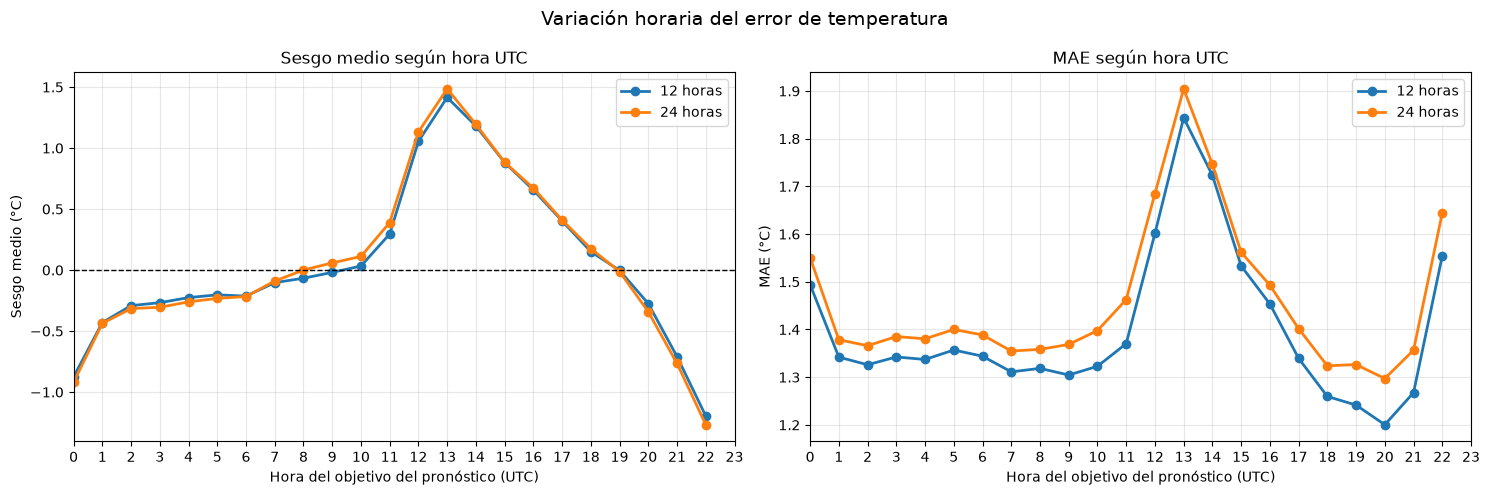

In [5]:

# ==========================================
# 5. GRÁFICOS DEL ERROR SEGÚN HORA UTC
# ==========================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 5)
)

for horizonte in [12, 24]:

    datos_h = resumen_horario_utc[
        resumen_horario_utc["horizon_target_hours"] == horizonte
    ].sort_values("hora_utc")

    # Sesgo medio
    axes[0].plot(
        datos_h["hora_utc"],
        datos_h["sesgo_medio_c"],
        marker="o",
        linewidth=2,
        label=f"{horizonte} horas"
    )

    # MAE
    axes[1].plot(
        datos_h["hora_utc"],
        datos_h["mae_c"],
        marker="o",
        linewidth=2,
        label=f"{horizonte} horas"
    )

# Referencia de sesgo cero
axes[0].axhline(
    0,
    color="black",
    linestyle="--",
    linewidth=1
)

axes[0].set_title("Sesgo medio según hora UTC")
axes[0].set_ylabel("Sesgo medio (°C)")

axes[1].set_title("MAE según hora UTC")
axes[1].set_ylabel("MAE (°C)")

for ax in axes:
    ax.set_xlabel("Hora del objetivo del pronóstico (UTC)")
    ax.set_xticks(range(24))
    ax.set_xlim(0, 23)
    ax.grid(True, alpha=0.3)
    ax.legend()

fig.suptitle(
    "Variación horaria del error de temperatura",
    fontsize=14
)

plt.tight_layout()
plt.show()


In [6]:

# ==========================================
# 6. CÁLCULO DE HORA SOLAR LOCAL APROXIMADA
# ==========================================

# Convertir longitud a valor numérico
df_temporal["longitude"] = pd.to_numeric(
    df_temporal["longitude"],
    errors="coerce"
)

# Comprobar disponibilidad y rango de longitudes
longitud_valida = df_temporal["longitude"].between(-180, 180)

print("REGISTROS CON LONGITUD VÁLIDA:")
print(longitud_valida.sum())

print("\nREGISTROS CON LONGITUD FALTANTE O INVÁLIDA:")
print((~longitud_valida).sum())

print("\nRANGO DE LONGITUDES:")
display(
    df_temporal.loc[
        longitud_valida, "longitude"
    ].agg(["min", "median", "max"])
)

# Calcular la hora UTC decimal del momento objetivo
hora_utc_decimal = (
    df_temporal["target_time_utc"].dt.hour
    + df_temporal["target_time_utc"].dt.minute / 60
    + df_temporal["target_time_utc"].dt.second / 3600
)

# Inicializar el resultado
df_temporal["hora_solar_decimal"] = np.nan

# Hora solar media local aproximada
df_temporal.loc[
    longitud_valida, "hora_solar_decimal"
] = (
    hora_utc_decimal.loc[longitud_valida]
    + df_temporal.loc[longitud_valida, "longitude"] / 15
) % 24

# Agrupar en horas solares enteras: 0 a 23
df_temporal["hora_solar"] = np.floor(
    df_temporal["hora_solar_decimal"]
).astype("Int64")

# Verificar cobertura de horas solares
print("\nHORAS SOLARES REPRESENTADAS POR HORIZONTE:")
display(
    df_temporal.groupby(
        "horizon_target_hours"
    )["hora_solar"].nunique()
)

print("\nREGISTROS SEGÚN HORA SOLAR:")
tabla_solar = pd.crosstab(
    df_temporal["hora_solar"],
    df_temporal["horizon_target_hours"]
)

display(
    tabla_solar.reindex(
        range(24),
        fill_value=0
    )
)

# Mostrar ejemplos de la transformación
print("\nEJEMPLOS DE CONVERSIÓN UTC A HORA SOLAR:")
display(
    df_temporal[
        [
            "station_id",
            "longitude",
            "hora_utc",
            "hora_solar_decimal",
            "hora_solar"
        ]
    ].dropna().sample(
        n=10,
        random_state=42
    ).round(2)
)


REGISTROS CON LONGITUD VÁLIDA:
854009

REGISTROS CON LONGITUD FALTANTE O INVÁLIDA:
0

RANGO DE LONGITUDES:


min      -91.29724
median   -77.94656
max      -67.43817
Name: longitude, dtype: float64


HORAS SOLARES REPRESENTADAS POR HORIZONTE:


horizon_target_hours
12    24
24    24
Name: hora_solar, dtype: int64


REGISTROS SEGÚN HORA SOLAR:


horizon_target_hours,12,24
hora_solar,,
0,18725,18818
1,18340,18340
2,18867,18876
3,18788,18788
4,19048,19042
5,18898,18902
6,18635,18915
7,17945,18082
8,18195,17992



EJEMPLOS DE CONVERSIÓN UTC A HORA SOLAR:


,station_id,longitude,hora_utc,hora_solar_decimal,hora_solar
205980,KUKF,-81.08,2,20.59,20
100211,VTWRL,-73.07,0,19.13,19
28575,KASH,-71.51,11,6.23,6
524210,AW457,-74.60,0,19.03,19
555361,KRBW,-80.64,6,0.62,0
395218,KMSV,-74.80,0,19.01,19
404071,KAXV,-84.30,11,5.38,5
533941,KBWI,-76.68,5,23.89,23
432322,G5310,-79.87,11,5.68,5
112764,KBJJ,-81.89,11,5.54,5


In [7]:

# ==========================================
# 7. ERROR SEGÚN HORA SOLAR LOCAL APROXIMADA
# ==========================================

# Agrupar por horizonte y hora solar
resumen_horario_solar = (
    df_temporal
    .dropna(subset=["hora_solar"])
    .groupby(
        ["horizon_target_hours", "hora_solar"]
    )
    .agg(
        registros=("error_c", "size"),
        fechas_distintas=("fecha_utc", "nunique"),
        estaciones=("station_id", "nunique"),
        sesgo_medio_c=("error_c", "mean"),
        mae_c=("error_abs_c", "mean")
    )
    .reset_index()
)

print("ERROR SEGÚN HORA SOLAR:")
display(resumen_horario_solar.round(3))

# Comprobar que no perdimos observaciones
print("\nCONTROL DE REGISTROS:")
display(
    resumen_horario_solar.groupby(
        "horizon_target_hours"
    )["registros"].sum()
)

# Identificar horarios con mayor y menor MAE
print("\nHORAS SOLARES CON MAYOR Y MENOR MAE:")

for horizonte in [12, 24]:

    datos_h = resumen_horario_solar[
        resumen_horario_solar[
            "horizon_target_hours"
        ] == horizonte
    ]

    mayor = datos_h.loc[
        datos_h["mae_c"].idxmax()
    ]

    menor = datos_h.loc[
        datos_h["mae_c"].idxmin()
    ]

    print(f"\nHorizonte {horizonte} horas:")

    print(
        f"Mayor MAE: hora solar "
        f"{int(mayor['hora_solar']):02d} "
        f"({mayor['mae_c']:.3f} °C)"
    )

    print(
        f"Menor MAE: hora solar "
        f"{int(menor['hora_solar']):02d} "
        f"({menor['mae_c']:.3f} °C)"
    )

# Evaluar diferencias de cobertura horaria
print("\nHORAS CON MENOR COBERTURA:")

display(
    resumen_horario_solar
    .sort_values(
        ["horizon_target_hours", "registros"]
    )
    .groupby("horizon_target_hours")
    .head(5)
    .round(3)
)


ERROR SEGÚN HORA SOLAR:


,horizon_target_hours,hora_solar,registros,fechas_distintas,estaciones,sesgo_medio_c,mae_c
0,12,0,18725,48,516,-0.219,1.346
1,12,1,18340,48,515,-0.154,1.319
2,12,2,18867,48,514,-0.072,1.304
3,12,3,18788,48,515,-0.023,1.303
4,12,4,19048,48,516,0.006,1.314
5,12,5,18898,48,513,0.166,1.340
6,12,6,18635,48,519,0.900,1.539
7,12,7,17945,48,518,1.391,1.844
8,12,8,18195,48,517,1.260,1.785
9,12,9,18636,48,518,0.954,1.579



CONTROL DE REGISTROS:


horizon_target_hours
12    427009
24    427000
Name: registros, dtype: int64


HORAS SOLARES CON MAYOR Y MENOR MAE:

Horizonte 12 horas:
Mayor MAE: hora solar 07 (1.844 °C)
Menor MAE: hora solar 14 (1.225 °C)

Horizonte 24 horas:
Mayor MAE: hora solar 07 (1.916 °C)
Menor MAE: hora solar 14 (1.307 °C)

HORAS CON MENOR COBERTURA:


,horizon_target_hours,hora_solar,registros,fechas_distintas,estaciones,sesgo_medio_c,mae_c
17,12,17,5476,48,165,-1.358,1.635
18,12,18,12687,48,353,-0.988,1.512
16,12,16,16977,48,500,-1.064,1.454
20,12,20,17339,48,511,-0.317,1.321
7,12,7,17945,48,518,1.391,1.844
41,24,17,5471,48,165,-1.470,1.733
42,24,18,12392,48,353,-1.009,1.565
40,24,16,16981,48,500,-1.134,1.545
44,24,20,17544,48,511,-0.336,1.362
32,24,8,17992,48,517,1.305,1.828


#### La cobertura geográfica es fundamental
Este es un hallazgo que tenemos que conservar para el informe.

| Hora solar |	Estaciones |	Registros 12 h |
|------------|-------------|-------------------|
| 07:00 |	518 |	17.945 |
| 14:00 |	518 |	18.822 |
| 16:00 |	500 |	16.977 |
| 17:00 |	165 |	5.476  |
|18:00	| 353	| 12.687 |

Esto significa que el sesgo muy negativo de las 17:00 podría estar influido por qué estaciones participan en ese horario, además del propio momento del día.

Por lo tanto, no debemos interpretar ese valor como representativo de toda la región sin realizar controles adicionales.


### 7.1. Interpretación del error según hora solar local

Se calculó la hora solar media local aproximada a partir de la hora UTC del objetivo y la longitud geográfica de cada estación.

La transformación permitió representar las 24 horas solares sin eliminar registros del conjunto original.

**Resultados principales:**

- Se conservaron 854.009 observaciones válidas.
- Todas las longitudes geográficas fueron válidas.
- El mayor MAE ocurrió a las 07:00 solares:
  - 12 horas: 1,844 °C.
  - 24 horas: 1,916 °C.
- El menor MAE ocurrió a las 14:00 solares:
  - 12 horas: 1,225 °C.
  - 24 horas: 1,307 °C.
- Durante las primeras horas de la mañana se observaron sesgos positivos importantes.
- Durante la tarde aparecieron sesgos negativos pronunciados.
- Los patrones fueron similares en ambos horizontes.

**Limitaciones de cobertura:**

La hora solar 17:00 presentó una representación geográfica reducida, con 165 estaciones, frente a más de 500 estaciones en la mayoría de los demás horarios.

Esta diferencia puede influir sobre los promedios y debe considerarse antes de interpretar los resultados.

La transformación solar no recupera las observaciones faltantes a las 23:00 UTC.

**Interpretación:**

Los resultados sugieren una asociación importante entre el momento solar del día y el error de temperatura.

El patrón es compatible con procesos de calentamiento y enfriamiento atmosférico, aunque no demuestra causalidad.

También podría estar influido por el desfase entre el intervalo pronosticado y el momento efectivo de observación.

**Implicancias para el modelado:**

La hora solar local aproximada se conservará como variable candidata.

Se evaluará una representación cíclica mediante seno y coseno.

La utilidad predictiva se comprobará con validación temporal y controles que consideren las diferencias de cobertura entre estaciones.


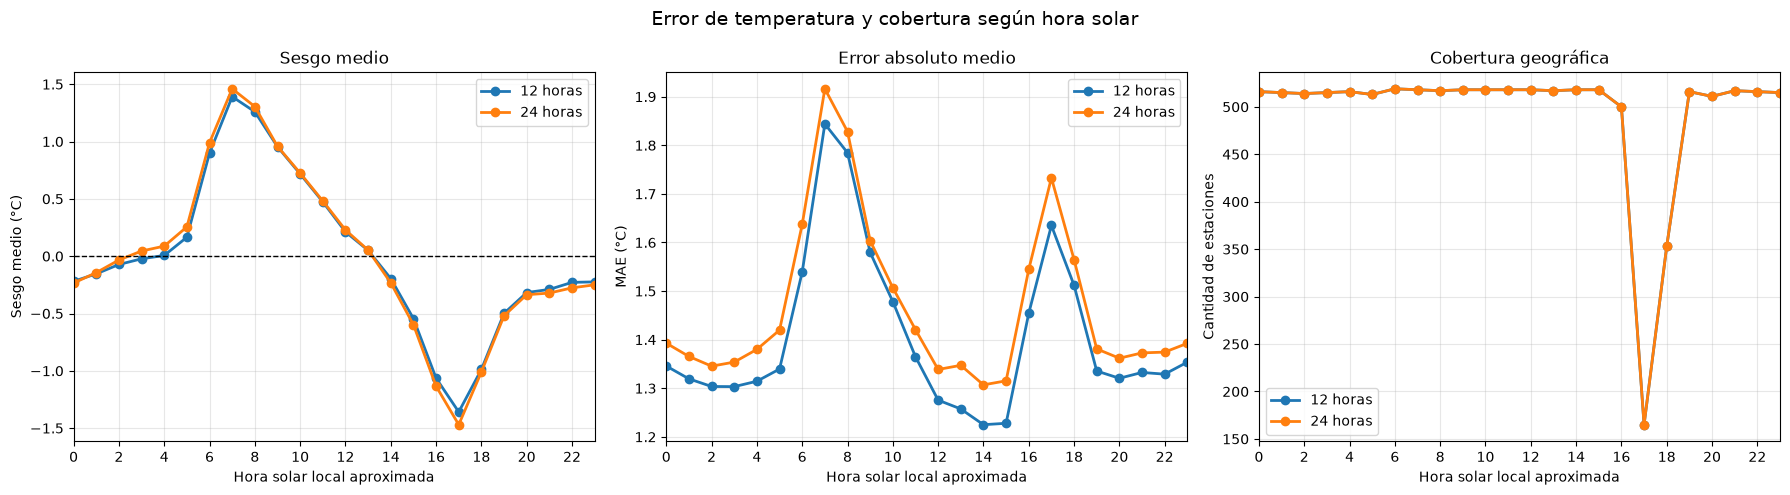

In [8]:

# ==========================================
# 8. GRÁFICOS DEL ERROR SEGÚN HORA SOLAR
# ==========================================

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 5)
)

for horizonte in [12, 24]:

    datos_h = resumen_horario_solar[
        resumen_horario_solar[
            "horizon_target_hours"
        ] == horizonte
    ].sort_values("hora_solar")

    # Sesgo medio
    axes[0].plot(
        datos_h["hora_solar"],
        datos_h["sesgo_medio_c"],
        marker="o",
        linewidth=2,
        label=f"{horizonte} horas"
    )

    # MAE
    axes[1].plot(
        datos_h["hora_solar"],
        datos_h["mae_c"],
        marker="o",
        linewidth=2,
        label=f"{horizonte} horas"
    )

    # Cobertura de estaciones
    axes[2].plot(
        datos_h["hora_solar"],
        datos_h["estaciones"],
        marker="o",
        linewidth=2,
        label=f"{horizonte} horas"
    )

# Línea de referencia del sesgo
axes[0].axhline(
    0,
    color="black",
    linestyle="--",
    linewidth=1
)

axes[0].set_title("Sesgo medio")
axes[0].set_ylabel("Sesgo medio (°C)")

axes[1].set_title("Error absoluto medio")
axes[1].set_ylabel("MAE (°C)")

axes[2].set_title("Cobertura geográfica")
axes[2].set_ylabel("Cantidad de estaciones")

for ax in axes:
    ax.set_xlabel("Hora solar local aproximada")
    ax.set_xticks(range(0, 24, 2))
    ax.set_xlim(0, 23)
    ax.grid(True, alpha=0.3)
    ax.legend()

fig.suptitle(
    "Error de temperatura y cobertura según hora solar",
    fontsize=14
)

plt.tight_layout()
plt.show()


Interpretación de los gráficos solares
1. Sesgo medio: un ciclo diario muy marcado
El gráfico izquierdo muestra que los pronósticos tienden a:
- Subestimar la temperatura durante la mañana solar, especialmente alrededor de las 07:00.
- Presentar un sesgo cercano a cero alrededor de las 13:00.
- Sobreestimar la temperatura durante la tarde, particularmente entre las 16:00 y las 18:00.

2. MAE: aparecen dos momentos críticos
MAE en horarios solares seleccionados
El mayor MAE aparece a las 07:00 solares, mientras que el menor se encuentra a las 14:00.

También observamos un segundo aumento importante alrededor de las 17:00, pero hay que interpretarlo con especial precaución

3. El tercer gráfico revela un problema de representatividad
La cantidad de estaciones cae considerablemente a las 17:00 solares.

| Hora solar |	Estaciones representadas |
|------------|---------------------------|
| 07:00 | 518 |
| 14:00 | 518 |
| 16:00 | 500 |
| 17:00 | 165 |
| 18:00 | 353 |
 
La hora 17 representa solo una parte de las estaciones. Además, sabemos que falta la hora 23:00 UTC, lo que contribuye a esta cobertura desigual después de la transformación solar.

Por eso, el segundo pico de error podría estar influido tanto por el horario como por las características de las estaciones representadas.

#### Controlar el efecto de las estaciones

Hasta ahora calculamos promedios de todas las observaciones disponibles en cada horario.

Ahora vamos a comparar las mismas estaciones entre pares de horas solares, evitando que una diferencia geográfica explique por sí sola los resultados.

Realizaremos dos comparaciones:
- 07:00 frente a 14:00: para comprobar si el error de la mañana sigue siendo mayor que el de la tarde cuando comparamos las mismas estaciones.
- 15:00 frente a 17:00: para investigar si el aumento del error a las 17:00 permanece cuando utilizamos únicamente estaciones representadas en ambos horarios.

In [10]:

# ==========================================
# 9. CONTROL DE COMPOSICIÓN DE ESTACIONES
# ==========================================

# Calcular estadísticas por estación, horizonte y hora solar
resumen_estacion_hora = (
    df_temporal
    .dropna(subset=["hora_solar"])
    .groupby(
        [
            "horizon_target_hours",
            "station_id",
            "hora_solar"
        ],
        observed=True
    )
    .agg(
        registros=("error_c", "size"),
        sesgo_c=("error_c", "mean"),
        mae_c=("error_abs_c", "mean")
    )
    .reset_index()
)

resultados_emparejados = []

# Comparar mañana vs tarde y dos horarios de tarde
for hora_a, hora_b in [(7, 14), (15, 17)]:

    # Estadísticas de la primera hora
    datos_a = (
        resumen_estacion_hora[
            resumen_estacion_hora["hora_solar"] == hora_a
        ]
        .drop(columns="hora_solar")
        .rename(columns={
            "registros": "registros_a",
            "sesgo_c": "sesgo_a",
            "mae_c": "mae_a"
        })
    )

    # Estadísticas de la segunda hora
    datos_b = (
        resumen_estacion_hora[
            resumen_estacion_hora["hora_solar"] == hora_b
        ]
        .drop(columns="hora_solar")
        .rename(columns={
            "registros": "registros_b",
            "sesgo_c": "sesgo_b",
            "mae_c": "mae_b"
        })
    )

    # Conservar únicamente estaciones presentes en ambas horas
    pares = datos_a.merge(
        datos_b,
        on=["horizon_target_hours", "station_id"],
        how="inner"
    )

    # Exigir un mínimo de cinco registros por hora
    pares = pares[
        (pares["registros_a"] >= 5)
        & (pares["registros_b"] >= 5)
    ].copy()

    for horizonte, grupo in pares.groupby("horizon_target_hours"):

        resultados_emparejados.append({
            "comparacion": f"{hora_a:02d}:00 vs {hora_b:02d}:00",
            "horizonte_h": horizonte,
            "estaciones_comunes": grupo["station_id"].nunique(),
            "sesgo_hora_a": grupo["sesgo_a"].mean(),
            "sesgo_hora_b": grupo["sesgo_b"].mean(),
            "mae_hora_a": grupo["mae_a"].mean(),
            "mae_hora_b": grupo["mae_b"].mean(),
            "diferencia_mae_b_menos_a": (
                grupo["mae_b"] - grupo["mae_a"]
            ).mean()
        })

# Mostrar resultados
df_emparejados = pd.DataFrame(resultados_emparejados)

print("COMPARACIÓN CON LAS MISMAS ESTACIONES:")
display(df_emparejados.round(3))


COMPARACIÓN CON LAS MISMAS ESTACIONES:


,comparacion,horizonte_h,estaciones_comunes,sesgo_hora_a,sesgo_hora_b,mae_hora_a,mae_hora_b,diferencia_mae_b_menos_a
0,07:00 vs 14:00,12,513,1.298,-0.196,1.797,1.238,-0.559
1,07:00 vs 14:00,24,513,1.358,-0.231,1.861,1.320,-0.541
2,15:00 vs 17:00,12,161,-0.356,-1.369,1.153,1.641,0.487
3,15:00 vs 17:00,24,161,-0.443,-1.488,1.243,1.742,0.499



### 9.1. Control de composición geográfica mediante estaciones emparejadas

Para comprobar si las diferencias horarias estaban influenciadas por la composición de estaciones, se compararon los errores de estaciones presentes en ambos horarios de cada comparación.

Se exigió un mínimo de cinco observaciones por estación y horario. Cada estación recibió el mismo peso en los promedios.

**Comparación 07:00 vs. 14:00 solares:**

- Se utilizaron 513 estaciones comunes por horizonte.
- A 12 horas, el MAE disminuyó de 1,797 °C a 1,238 °C, una diferencia de −0,559 °C.
- A 24 horas, el MAE disminuyó de 1,861 °C a 1,320 °C, una diferencia de −0,541 °C.
- El sesgo pasó de positivo durante la mañana a ligeramente negativo durante la tarde.

**Comparación 15:00 vs. 17:00 solares:**

- Se utilizaron 161 estaciones comunes por horizonte.
- A 12 horas, el MAE aumentó de 1,153 °C a 1,641 °C.
- A 24 horas, el MAE aumentó de 1,243 °C a 1,742 °C.
- El sesgo se volvió considerablemente más negativo a las 17:00.

**Interpretación:**

Las diferencias horarias persistieron al comparar las mismas estaciones, lo que indica que no se explican exclusivamente por la composición geográfica.

Sin embargo, las observaciones no fueron emparejadas por fecha y condiciones meteorológicas. Por lo tanto, los resultados no permiten establecer una relación causal.

**Implicancias:**

Se conservará la hora solar media local como variable predictora candidata.

Su contribución deberá evaluarse mediante validación temporal y controles adicionales sobre las condiciones meteorológicas y la disponibilidad de observaciones.


In [11]:

# ==========================================
# 10. ANÁLISIS DIARIO DEL ERROR DE TEMPERATURA
# ==========================================

# Agrupar por fecha objetivo y horizonte
resumen_diario = (
    df_temporal
    .groupby(
        ["fecha_utc", "horizon_target_hours"]
    )
    .agg(
        registros=("error_c", "size"),
        estaciones=("station_id", "nunique"),
        sesgo_medio_c=("error_c", "mean"),
        mae_c=("error_abs_c", "mean")
    )
    .reset_index()
    .sort_values(
        ["fecha_utc", "horizon_target_hours"]
    )
)

# Comprobar cantidad de fechas
print("FECHAS DISTINTAS POR HORIZONTE:")

display(
    resumen_diario.groupby(
        "horizon_target_hours"
    )["fecha_utc"].nunique()
)

# Identificar fechas sin registros
fechas_presentes = pd.to_datetime(
    resumen_diario["fecha_utc"].unique()
)

calendario = pd.date_range(
    start=fechas_presentes.min(),
    end=fechas_presentes.max(),
    freq="D"
)

fechas_ausentes = calendario.difference(
    fechas_presentes
)

print("\nFECHAS AUSENTES EN EL PERÍODO:")
print(fechas_ausentes.strftime("%Y-%m-%d").tolist())

# Estadísticas generales de los errores diarios
print("\nDISTRIBUCIÓN DEL MAE DIARIO:")

display(
    resumen_diario.groupby(
        "horizon_target_hours"
    )["mae_c"]
    .agg(["min", "median", "mean", "max"])
    .round(3)
)

# Identificar los tres días de mayor MAE por horizonte
print("\nTRES DÍAS DE MAYOR MAE POR HORIZONTE:")

display(
    resumen_diario
    .sort_values("mae_c", ascending=False)
    .groupby("horizon_target_hours")
    .head(3)
    .sort_values(
        ["horizon_target_hours", "mae_c"],
        ascending=[True, False]
    )
    .round(3)
)

# Mostrar una muestra cronológica
print("\nPRIMEROS Y ÚLTIMOS DÍAS:")

display(
    pd.concat([
        resumen_diario.head(6),
        resumen_diario.tail(6)
    ]).round(3)
)


FECHAS DISTINTAS POR HORIZONTE:


horizon_target_hours
12    48
24    48
Name: fecha_utc, dtype: int64


FECHAS AUSENTES EN EL PERÍODO:
['2026-10-22', '2026-10-23', '2026-10-24', '2026-10-25', '2026-10-26']

DISTRIBUCIÓN DEL MAE DIARIO:


,min,median,mean,max
horizon_target_hours,,,,
12,1.143,1.389,1.397,1.919
24,1.125,1.431,1.454,1.869



TRES DÍAS DE MAYOR MAE POR HORIZONTE:


,fecha_utc,horizon_target_hours,registros,estaciones,sesgo_medio_c,mae_c
80,2026-10-20,12,8196,508,0.039,1.919
82,2026-10-21,12,9677,508,0.063,1.827
78,2026-10-19,12,8077,506,-0.249,1.740
83,2026-10-21,24,9677,508,-0.061,1.869
79,2026-10-19,24,8077,506,-0.097,1.803
81,2026-10-20,24,8196,508,-0.031,1.799



PRIMEROS Y ÚLTIMOS DÍAS:


,fecha_utc,horizon_target_hours,registros,estaciones,sesgo_medio_c,mae_c
0,2026-09-10,12,8311,511,0.246,1.163
1,2026-09-10,24,8311,511,0.378,1.223
2,2026-09-11,12,8026,469,0.194,1.311
3,2026-09-11,24,8026,469,0.318,1.438
4,2026-09-12,12,8254,510,-0.237,1.367
5,2026-09-12,24,8254,510,-0.235,1.414
90,2026-10-30,12,8853,507,0.357,1.470
91,2026-10-30,24,8853,507,0.309,1.478
92,2026-10-31,12,9557,506,0.302,1.447
93,2026-10-31,24,9557,506,0.169,1.435



### 10.1. Interpretación de la evolución diaria del error

Se estudió la evolución diaria del error de temperatura para los horizontes de 12 y 24 horas.

**Cobertura temporal:**

- Se analizaron 48 fechas entre el 10 de septiembre y el 1 de noviembre de 2026.
- Se confirmó la exclusión de los días 22 al 26 de octubre de 2026.
- Ambos horizontes conservaron las mismas 48 fechas.

**Resultados:**

- El MAE diario presentó variaciones considerables.
- Para 12 horas, el MAE osciló entre 1,143 °C y 1,919 °C.
- Para 24 horas, el MAE osciló entre 1,125 °C y 1,869 °C.
- Los tres días de mayor MAE en ambos horizontes correspondieron al 19, 20 y 21 de octubre.
- Esos días contaron con aproximadamente 506–508 estaciones representadas.

**Interpretación:**

La magnitud del error no fue constante a lo largo del período estudiado.

La concentración de errores elevados entre el 19 y el 21 de octubre constituye un hallazgo exploratorio que requiere cautela, especialmente por su proximidad al período excluido durante la auditoría de calidad.

No se dispone todavía de evidencia suficiente para atribuir esos errores a una situación meteorológica específica ni a la anomalía de calidad detectada posteriormente.

**Implicancias para el modelado:**

La evolución temporal del error justifica evaluar la estabilidad de los modelos en distintos períodos.

La división entre entrenamiento, validación y prueba deberá respetar el orden cronológico.

No se utilizarán promedios de error calculados con fechas futuras como variables predictoras de períodos anteriores.


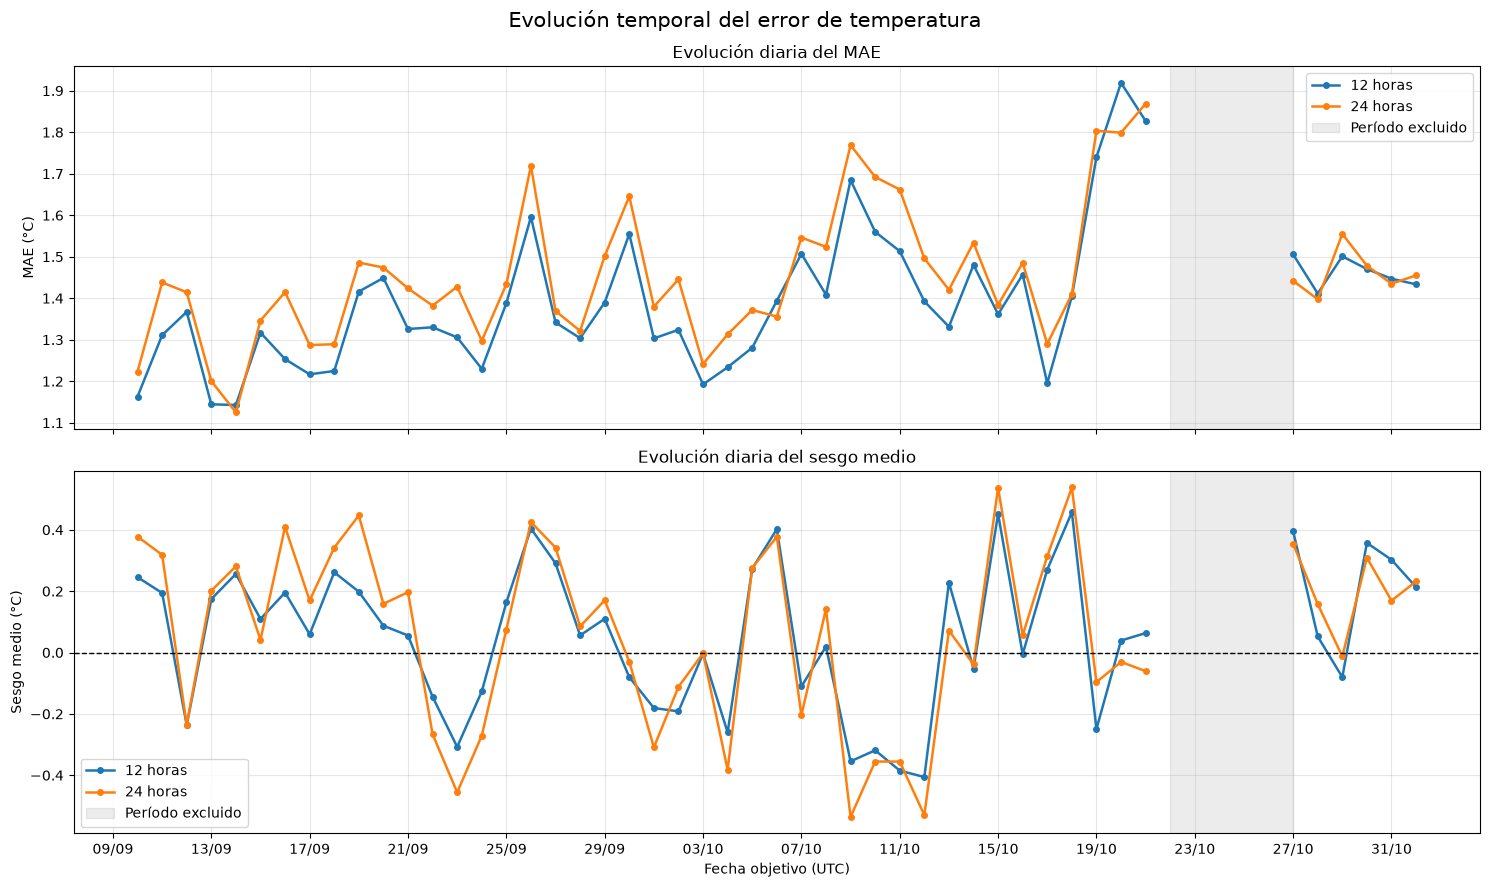

In [12]:

# ==========================================
# 11. EVOLUCIÓN DIARIA DEL ERROR
# ==========================================

import matplotlib.dates as mdates

# Preparar datos
datos_diarios = resumen_diario.copy()

datos_diarios["fecha_utc"] = pd.to_datetime(
    datos_diarios["fecha_utc"]
)

# Crear calendario completo, incluyendo fechas ausentes
calendario_completo = pd.date_range(
    start=datos_diarios["fecha_utc"].min(),
    end=datos_diarios["fecha_utc"].max(),
    freq="D"
)

# Organizar valores diarios
tabla_mae = datos_diarios.pivot(
    index="fecha_utc",
    columns="horizon_target_hours",
    values="mae_c"
).reindex(calendario_completo)

tabla_sesgo = datos_diarios.pivot(
    index="fecha_utc",
    columns="horizon_target_hours",
    values="sesgo_medio_c"
).reindex(calendario_completo)

# Crear gráficos
fig, axes = plt.subplots(
    2, 1,
    figsize=(15, 9),
    sharex=True
)

for horizonte in [12, 24]:

    # MAE
    axes[0].plot(
        tabla_mae.index,
        tabla_mae[horizonte],
        marker="o",
        markersize=4,
        linewidth=1.8,
        label=f"{horizonte} horas"
    )

    # Sesgo
    axes[1].plot(
        tabla_sesgo.index,
        tabla_sesgo[horizonte],
        marker="o",
        markersize=4,
        linewidth=1.8,
        label=f"{horizonte} horas"
    )

# Línea de referencia del sesgo
axes[1].axhline(
    0,
    color="black",
    linestyle="--",
    linewidth=1
)

# Señalar el período excluido
for ax in axes:
    ax.axvspan(
        pd.Timestamp("2026-10-22"),
        pd.Timestamp("2026-10-27"),
        color="gray",
        alpha=0.15,
        label="Período excluido"
    )

    ax.grid(True, alpha=0.3)
    ax.legend()

axes[0].set_title("Evolución diaria del MAE")
axes[0].set_ylabel("MAE (°C)")

axes[1].set_title("Evolución diaria del sesgo medio")
axes[1].set_ylabel("Sesgo medio (°C)")
axes[1].set_xlabel("Fecha objetivo (UTC)")

# Formato de las fechas
axes[1].xaxis.set_major_locator(
    mdates.DayLocator(interval=4)
)

axes[1].xaxis.set_major_formatter(
    mdates.DateFormatter("%d/%m")
)

fig.suptitle(
    "Evolución temporal del error de temperatura",
    fontsize=15
)

plt.tight_layout()
plt.show()


Interpretación de la evolución diaria
1. Gráfico superior: evolución del MAE
Observamos que los errores no aumentan ni disminuyen de manera uniforme durante el período.

El resultado más llamativo es la concentración de errores elevados entre el 19 y el 21 de octubre.
Fecha	MAE 12 h	MAE 24 h
19/10	1,740 °C	1,803 °C
20/10	1,919 °C	1,799 °C
21/10	1,827 °C	1,869 °C

También se observan otros aumentos en septiembre y principios de octubre.

Esto indica que existen días en los que los pronósticos presentan mayor dificultad, pero no sabemos todavía qué condiciones meteorológicas explican esas diferencias.
2. Gráfico inferior: evolución del sesgo
El segundo gráfico aporta una conclusión importante.

El sesgo cambia de positivo a negativo repetidamente a lo largo de las fechas.

Recordemos:
- Sesgo positivo: el pronóstico subestima la temperatura.
- Sesgo negativo: el pronóstico sobreestima la temperatura.
- Sesgo cercano a cero: no hay una desviación media importante, aunque los errores individuales pueden seguir siendo elevados.
Esto explica por qué el sesgo global del Notebook 01 era pequeño, pese a que los errores absolutos eran considerables.

Implicancia: una corrección global constante probablemente no alcance para representar todas las condiciones. Tenemos motivos para evaluar correcciones que consideren información temporal y meteorológica.
3. Comparación entre horizontes
Las dos curvas de MAE evolucionan de manera similar. La de 24 horas suele estar por encima de la de 12 horas, aunque no siempre.

Por ejemplo, el 20 de octubre el MAE de 12 horas supera al de 24 horas.

Por lo tanto, no corresponde afirmar que el horizonte de 24 horas es peor en todas las situaciones.
4. ¿Debemos investigar más el período 19–21 de octubre?
Conviene conservarlo como un período de interés, pero no excluirlo automáticamente.

Estos días presentan errores elevados, pero eso no demuestra un problema de calidad de datos. Podrían corresponder a situaciones meteorológicas difíciles.

La exclusión del 22–26 de octubre se justificó por una anomalía de calidad previamente identificada, no por valores elevados de MAE.

Mi propuesta es mantener el 19–21 de octubre en el dataset y revisar después el desempeño de los modelos sobre ese período, siempre que corresponda a una partición temporal evaluable.


### 11.1. Interpretación gráfica de la evolución diaria

Se representaron el MAE y el sesgo medio diario para los horizontes de 12 y 24 horas, considerando las 48 fechas seleccionadas.

**Resultados principales:**

- El MAE presentó variaciones considerables entre diferentes fechas.
- Las curvas de 12 y 24 horas tuvieron comportamientos temporales similares.
- Los mayores errores se concentraron entre el 19 y el 21 de octubre.
- El horizonte de 24 horas presentó generalmente errores superiores, aunque existieron excepciones.
- El sesgo medio cambió de signo en numerosas ocasiones.
- Los cinco días excluidos entre el 22 y el 26 de octubre se mantuvieron ausentes y fueron identificados visualmente.

**Interpretación:**

La precisión del pronóstico no fue constante durante el período estudiado.

El sesgo diario presentó variaciones que podrían estar relacionadas con las condiciones meteorológicas, los cambios temporales y la composición de observaciones disponibles.

La concentración de errores elevados antes del período excluido constituye un hallazgo exploratorio, pero no demuestra que esos días presenten problemas de calidad.

**Implicancias para el modelado:**

Se conservarán las fechas válidas del 19 al 21 de octubre.

La evaluación de los modelos deberá respetar el orden cronológico y comprobar si las correcciones funcionan de manera consistente en diferentes períodos.

Las fechas podrán utilizarse para construir variables temporales conocidas al momento de la predicción, pero nunca se utilizará el error real de fechas futuras como predictor.


In [13]:

# ==========================================
# 12. VARIABLES TEMPORALES CÍCLICAS
# ==========================================

# Utilizar las horas derivadas del momento objetivo
hora_utc_decimal = (
    df_temporal["target_time_utc"].dt.hour
    + df_temporal["target_time_utc"].dt.minute / 60
    + df_temporal["target_time_utc"].dt.second / 3600
)

hora_solar_decimal = df_temporal["hora_solar_decimal"]

# Representación cíclica de la hora UTC
df_temporal["hora_utc_sin"] = np.sin(
    2 * np.pi * hora_utc_decimal / 24
)

df_temporal["hora_utc_cos"] = np.cos(
    2 * np.pi * hora_utc_decimal / 24
)

# Representación cíclica de la hora solar
df_temporal["hora_solar_sin"] = np.sin(
    2 * np.pi * hora_solar_decimal / 24
)

df_temporal["hora_solar_cos"] = np.cos(
    2 * np.pi * hora_solar_decimal / 24
)

# Verificar que las cuatro variables estén completas
columnas_ciclicas = [
    "hora_utc_sin",
    "hora_utc_cos",
    "hora_solar_sin",
    "hora_solar_cos"
]

print("VALORES FALTANTES:")
display(
    df_temporal[columnas_ciclicas].isna().sum()
)

# Verificar identidad trigonométrica: sin² + cos² = 1
control_utc = (
    df_temporal["hora_utc_sin"]**2
    + df_temporal["hora_utc_cos"]**2
)

control_solar = (
    df_temporal["hora_solar_sin"]**2
    + df_temporal["hora_solar_cos"]**2
)

print("\nDESVIACIÓN MÁXIMA RESPECTO DE 1:")
print(
    "UTC:",
    np.abs(control_utc - 1).max()
)
print(
    "Solar:",
    np.abs(control_solar - 1).max()
)

# Ejemplos de las nuevas variables
print("\nEJEMPLOS DE VARIABLES CÍCLICAS:")

display(
    df_temporal[
        [
            "hora_utc",
            "hora_solar_decimal",
            "hora_utc_sin",
            "hora_utc_cos",
            "hora_solar_sin",
            "hora_solar_cos"
        ]
    ].sample(
        n=10,
        random_state=42
    ).round(3)
)

print("\nTOTAL DE REGISTROS:")
print(len(df_temporal))


VALORES FALTANTES:


hora_utc_sin      0
hora_utc_cos      0
hora_solar_sin    0
hora_solar_cos    0
dtype: int64


DESVIACIÓN MÁXIMA RESPECTO DE 1:
UTC: 2.220446049250313e-16
Solar: 2.220446049250313e-16

EJEMPLOS DE VARIABLES CÍCLICAS:


,hora_utc,hora_solar_decimal,hora_utc_sin,hora_utc_cos,hora_solar_sin,hora_solar_cos
205980,2,20.594,0.500,0.866,-0.778,0.628
100211,0,19.129,0.000,1.000,-0.957,0.291
28575,11,6.232,0.259,-0.966,0.998,-0.061
524210,0,19.027,0.000,1.000,-0.964,0.266
555361,6,0.624,1.000,0.000,0.163,0.987
395218,0,19.013,0.000,1.000,-0.965,0.262
404071,11,5.380,0.259,-0.966,0.987,0.162
533941,5,23.888,0.966,0.259,-0.029,1.000
432322,11,5.675,0.259,-0.966,0.996,0.085
112764,11,5.541,0.259,-0.966,0.993,0.120



TOTAL DE REGISTROS:
854009


In [14]:

# ==========================================
# 13. AUDITORÍA TEMPORAL PREVIA A LOS LAGS
# ==========================================

columnas_auditoria = [
    "horizon_target_hours",
    "match_type",
    "snapshot_time_utc",
    "forecast_generated_at_utc",
    "target_time_utc",
    "observation_time_utc",
    "observation_collection_hour_utc",
    "temperature_forecast_c",
    "temperature_observed_c"
]

fragmentos_auditoria = []

# Analizar el primer y último archivo seleccionado
for archivo in [
    archivos_analisis[0],
    archivos_analisis[-1]
]:

    for bloque in pd.read_csv(
        archivo,
        usecols=columnas_auditoria,
        chunksize=100_000
    ):

        filtro = (
            bloque["horizon_target_hours"].isin([12, 24])
            & bloque["match_type"].eq("interval")
            & bloque["temperature_forecast_c"].notna()
            & bloque["temperature_observed_c"].notna()
        )

        seleccion = bloque.loc[filtro].copy()

        if not seleccion.empty:
            seleccion["archivo"] = archivo.stem
            fragmentos_auditoria.append(seleccion)

df_auditoria_lags = pd.concat(
    fragmentos_auditoria,
    ignore_index=True
)

del fragmentos_auditoria

# Convertir fechas
columnas_fecha = [
    "snapshot_time_utc",
    "forecast_generated_at_utc",
    "target_time_utc",
    "observation_time_utc",
    "observation_collection_hour_utc"
]

for columna in columnas_fecha:
    df_auditoria_lags[columna] = pd.to_datetime(
        df_auditoria_lags[columna],
        utc=True,
        errors="coerce"
    )

# Diferencia entre generación informada y snapshot
df_auditoria_lags["generacion_desde_snapshot_min"] = (
    df_auditoria_lags["forecast_generated_at_utc"]
    - df_auditoria_lags["snapshot_time_utc"]
).dt.total_seconds() / 60

# Diferencia entre observación y objetivo
df_auditoria_lags["observacion_desde_objetivo_min"] = (
    df_auditoria_lags["observation_time_utc"]
    - df_auditoria_lags["target_time_utc"]
).dt.total_seconds() / 60

# Diferencia entre hora de recolección y observación
df_auditoria_lags["recoleccion_desde_observacion_min"] = (
    df_auditoria_lags["observation_collection_hour_utc"]
    - df_auditoria_lags["observation_time_utc"]
).dt.total_seconds() / 60

# Verificar valores faltantes
print("FECHAS FALTANTES:")
display(
    df_auditoria_lags[columnas_fecha].isna().sum()
)

# Resumen por horizonte
print("\nDIFERENCIAS TEMPORALES EN MINUTOS:")

display(
    df_auditoria_lags.groupby(
        "horizon_target_hours"
    )[
        [
            "generacion_desde_snapshot_min",
            "observacion_desde_objetivo_min",
            "recoleccion_desde_observacion_min"
        ]
    ].agg(
        ["min", "median", "max"]
    ).round(2)
)

# Comprobar si la generación informada
# puede ser posterior al snapshot
print("\nPRONÓSTICOS GENERADOS DESPUÉS DEL SNAPSHOT:")

display(
    df_auditoria_lags.assign(
        posterior=(
            df_auditoria_lags["forecast_generated_at_utc"]
            > df_auditoria_lags["snapshot_time_utc"]
        )
    ).groupby(
        "horizon_target_hours"
    )["posterior"].agg(["sum", "mean"]).round(4)
)

print("\nREGISTROS ANALIZADOS POR ARCHIVO:")
display(
    pd.crosstab(
        df_auditoria_lags["archivo"],
        df_auditoria_lags["horizon_target_hours"]
    )
)


FECHAS FALTANTES:


snapshot_time_utc                  0
forecast_generated_at_utc          0
target_time_utc                    0
observation_time_utc               0
observation_collection_hour_utc    0
dtype: int64


DIFERENCIAS TEMPORALES EN MINUTOS:


generacion_desde_snapshot_min                \
                                               min median    max   
horizon_target_hours                                               
12                                          -59.95  14.75  20.82   
24                                          -59.93   1.68  25.58   

                     observacion_desde_objetivo_min               \
                                                min median   max   
horizon_target_hours                                               
12                                              0.0   38.0  59.0   
24                                              0.0   38.0  59.0   

                     recoleccion_desde_observacion_min                 
                                                   min median     max  
horizon_target_hours                                                   
12                                                 5.0   25.0  1300.0  
24                                                 5.0   25.0  1300.0


PRONÓSTICOS GENERADOS DESPUÉS DEL SNAPSHOT:


,sum,mean
horizon_target_hours,,
12,9320,0.5432
24,8703,0.5073



REGISTROS ANALIZADOS POR ARCHIVO:


horizon_target_hours,12,24
archivo,,
forecast_observation_2026_09_10,8311,8311
forecast_observation_2026_11_01,8847,8846



### 13.1. Auditoría de disponibilidad temporal para variables lag

Se analizaron registros válidos de los horizontes de 12 y 24 horas correspondientes al primer y último archivo seleccionado.

El objetivo fue comprobar la relación temporal entre la generación del pronóstico, su momento nominal de referencia y las observaciones utilizadas.

**Resultados:**

- No se identificaron valores faltantes en las cinco columnas temporales examinadas.
- La generación informada del pronóstico puede ocurrir antes o después del snapshot nominal.
- El 54,32 % de los pronósticos de 12 horas y el 50,73 % de los pronósticos de 24 horas presentaron una generación posterior al snapshot.
- Las observaciones ocurrieron entre 0 y 59 minutos después del momento objetivo, con mediana de 38 minutos.
- La diferencia entre la hora de recolección de la observación y su momento efectivo presentó una mediana de 25 minutos y un máximo de 1.300 minutos.

**Interpretación metodológica:**

El horizonte nominal no representa necesariamente la anticipación exacta desde la generación informada del pronóstico.

Las variables de error histórico deben construirse considerando la disponibilidad temporal de las observaciones y no solamente la diferencia entre fechas objetivo.

Las marcas de recolección disponibles requieren una interpretación cuidadosa y no deben asumirse automáticamente como instantes exactos de disponibilidad operativa.

**Implicancias para el modelado:**

No se construirán lags mediante desplazamientos de filas sin comprobar previamente la cronología.

Se investigará la distribución de los retrasos de recolección y posteriormente se definirá una regla conservadora para utilizar únicamente información histórica que pueda considerarse disponible al momento de cada pronóstico.

La auditoría realizada sobre dos archivos es exploratoria y no sustituye la verificación del conjunto completo.


In [15]:

# ==========================================
# 14. AUDITORÍA DE RETRASOS DE OBSERVACIONES
# ==========================================

columna = "recoleccion_desde_observacion_min"

# Distribución por horizonte
print("PERCENTILES DEL DESFASE EN MINUTOS:")

percentiles_retraso = (
    df_auditoria_lags
    .groupby("horizon_target_hours")[columna]
    .quantile([0.50, 0.90, 0.95, 0.99, 1.00])
    .unstack()
)

percentiles_retraso.columns = [
    "P50", "P90", "P95", "P99", "Máximo"
]

display(percentiles_retraso.round(2))

# Cantidad de registros que superan distintos umbrales
resultados_retrasos = []

for horizonte in [12, 24]:

    datos_h = df_auditoria_lags[
        df_auditoria_lags[
            "horizon_target_hours"
        ] == horizonte
    ]

    retrasos = datos_h[columna]

    resultados_retrasos.append({
        "horizonte_h": horizonte,
        "registros": len(datos_h),
        "mayor_60_min": (retrasos > 60).sum(),
        "mayor_120_min": (retrasos > 120).sum(),
        "mayor_360_min": (retrasos > 360).sum(),
        "mayor_720_min": (retrasos > 720).sum(),
        "porcentaje_mayor_60": (
            (retrasos > 60).mean() * 100
        )
    })

print("\nFRECUENCIA DE RETRASOS ELEVADOS:")

display(
    pd.DataFrame(resultados_retrasos).round(3)
)

# Inspeccionar los casos extremos
print("\nDIEZ MAYORES DESFASES:")

display(
    df_auditoria_lags.nlargest(
        10, columna
    )[
        [
            "archivo",
            "horizon_target_hours",
            "target_time_utc",
            "observation_time_utc",
            "observation_collection_hour_utc",
            columna
        ]
    ]
)


PERCENTILES DEL DESFASE EN MINUTOS:


,P50,P90,P95,P99,Máximo
horizon_target_hours,,,,,
12,25.0,64.0,77.0,120.0,1300.0
24,25.0,64.0,77.0,120.0,1300.0



FRECUENCIA DE RETRASOS ELEVADOS:


,horizonte_h,registros,mayor_60_min,mayor_120_min,mayor_360_min,mayor_720_min,porcentaje_mayor_60
0,12,17158,1850,147,11,2,10.782
1,24,17157,1850,147,11,2,10.783



DIEZ MAYORES DESFASES:


,archivo,horizon_target_hours,target_time_utc,observation_time_utc,observation_collection_hour_utc,recoleccion_desde_observacion_min
17358,forecast_observation_2026_11_01,24,2026-11-01 01:00:00+00:00,2026-11-01 01:20:00+00:00,2026-11-01 23:00:00+00:00,1300.0
22973,forecast_observation_2026_11_01,12,2026-11-01 01:00:00+00:00,2026-11-01 01:20:00+00:00,2026-11-01 23:00:00+00:00,1300.0
1952,forecast_observation_2026_09_10,24,2026-09-10 04:00:00+00:00,2026-09-10 04:00:00+00:00,2026-09-10 23:00:00+00:00,1140.0
8174,forecast_observation_2026_09_10,12,2026-09-10 04:00:00+00:00,2026-09-10 04:00:00+00:00,2026-09-10 23:00:00+00:00,1140.0
798,forecast_observation_2026_09_10,24,2026-09-10 02:00:00+00:00,2026-09-10 02:27:00+00:00,2026-09-10 14:00:00+00:00,693.0
6030,forecast_observation_2026_09_10,12,2026-09-10 02:00:00+00:00,2026-09-10 02:27:00+00:00,2026-09-10 14:00:00+00:00,693.0
4405,forecast_observation_2026_09_10,24,2026-09-10 11:00:00+00:00,2026-09-10 11:53:00+00:00,2026-09-10 23:00:00+00:00,667.0
12716,forecast_observation_2026_09_10,12,2026-09-10 11:00:00+00:00,2026-09-10 11:53:00+00:00,2026-09-10 23:00:00+00:00,667.0
4674,forecast_observation_2026_09_10,24,2026-09-10 12:00:00+00:00,2026-09-10 12:50:00+00:00,2026-09-10 23:00:00+00:00,610.0
12867,forecast_observation_2026_09_10,12,2026-09-10 12:00:00+00:00,2026-09-10 12:50:00+00:00,2026-09-10 23:00:00+00:00,610.0


In [16]:

# ==========================================
# 15. PREPARACIÓN DE DATOS PARA LAGS
# ==========================================

columnas_lags = [
    "station_id",
    "horizon_target_hours",
    "match_type",
    "snapshot_time_utc",
    "forecast_generated_at_utc",
    "target_time_utc",
    "observation_time_utc",
    "observation_collection_hour_utc",
    "temperature_forecast_c",
    "temperature_observed_c"
]

fragmentos_lags = []

for archivo in archivos_analisis:

    for bloque in pd.read_csv(
        archivo,
        usecols=columnas_lags,
        chunksize=100_000
    ):

        filtro = (
            bloque["horizon_target_hours"].isin([12, 24])
            & bloque["match_type"].eq("interval")
            & bloque["temperature_forecast_c"].notna()
            & bloque["temperature_observed_c"].notna()
        )

        seleccion = bloque.loc[
            filtro,
            [c for c in columnas_lags if c != "match_type"]
        ].copy()

        if not seleccion.empty:
            fragmentos_lags.append(seleccion)

df_base_lags = pd.concat(
    fragmentos_lags,
    ignore_index=True
)

del fragmentos_lags

# Convertir marcas temporales
columnas_fechas_lags = [
    "snapshot_time_utc",
    "forecast_generated_at_utc",
    "target_time_utc",
    "observation_time_utc",
    "observation_collection_hour_utc"
]

for columna in columnas_fechas_lags:
    df_base_lags[columna] = pd.to_datetime(
        df_base_lags[columna],
        utc=True,
        errors="coerce"
    )

# Calcular el error histórico
df_base_lags["error_c"] = (
    df_base_lags["temperature_observed_c"]
    - df_base_lags["temperature_forecast_c"]
)

# Controles
print("TOTAL DE REGISTROS:")
print(len(df_base_lags))

print("\nREGISTROS POR HORIZONTE:")
display(
    df_base_lags[
        "horizon_target_hours"
    ].value_counts().sort_index()
)

print("\nFECHAS TEMPORALES FALTANTES:")
display(
    df_base_lags[columnas_fechas_lags].isna().sum()
)

# Verificar unicidad de la clave candidata
clave = [
    "station_id",
    "horizon_target_hours",
    "target_time_utc"
]

duplicados = df_base_lags.duplicated(
    subset=clave,
    keep=False
)

print("\nFILAS CON CLAVE CANDIDATA DUPLICADA:")
print(duplicados.sum())

print("\nCOMBINACIONES DE CLAVE DUPLICADAS:")
print(
    df_base_lags.loc[
        duplicados, clave
    ].drop_duplicates().shape[0]
)

# Verificar orden temporal de la observación
print("\nRECOLECCIÓN ANTERIOR A LA OBSERVACIÓN:")
print(
    (
        df_base_lags["observation_collection_hour_utc"]
        < df_base_lags["observation_time_utc"]
    ).sum()
)


TOTAL DE REGISTROS:
854009

REGISTROS POR HORIZONTE:


horizon_target_hours
12    427009
24    427000
Name: count, dtype: int64


FECHAS TEMPORALES FALTANTES:


snapshot_time_utc                  0
forecast_generated_at_utc          0
target_time_utc                    0
observation_time_utc               0
observation_collection_hour_utc    0
dtype: int64


FILAS CON CLAVE CANDIDATA DUPLICADA:
0

COMBINACIONES DE CLAVE DUPLICADAS:
0

RECOLECCIÓN ANTERIOR A LA OBSERVACIÓN:
0


In [17]:

# ==========================================
# 16. DISPONIBILIDAD DE LAGS HISTÓRICOS
# ==========================================

# Clave única comprobada previamente
clave_historica = [
    "station_id",
    "horizon_target_hours",
    "target_time_utc"
]

# Tabla de errores históricos
historico = df_base_lags.set_index(
    clave_historica
)[
    [
        "error_c",
        "observation_time_utc",
        "observation_collection_hour_utc"
    ]
]

if not historico.index.is_unique:
    raise ValueError("La clave histórica no es única.")

resultados_lags = []

for horizonte in [12, 24]:

    # Pronósticos que queremos corregir
    base_h = df_base_lags.loc[
        df_base_lags["horizon_target_hours"] == horizonte,
        ["station_id", "snapshot_time_utc"]
    ].reset_index(drop=True)

    for lag_horas in [12, 24]:

        # El antecedente debe estar 12 o 24 horas
        # ANTES del snapshot nominal
        momento_historico = (
            base_h["snapshot_time_utc"]
            - pd.Timedelta(hours=lag_horas)
        )

        # Buscar misma estación y mismo horizonte
        claves_busqueda = pd.MultiIndex.from_arrays(
            [
                base_h["station_id"],
                np.full(len(base_h), horizonte),
                momento_historico
            ],
            names=clave_historica
        )

        candidatos = historico.reindex(
            claves_busqueda
        ).reset_index(drop=True)

        # Existe un antecedente en el dataset
        existe = candidatos["error_c"].notna()

        # La observación ocurrió antes del snapshot
        observacion_anterior = (
            candidatos["observation_time_utc"]
            < base_h["snapshot_time_utc"]
        )

        # Su marca de recolección también es anterior
        recoleccion_anterior = (
            candidatos["observation_collection_hour_utc"]
            < base_h["snapshot_time_utc"]
        )

        # Regla conservadora de disponibilidad
        disponible = (
            existe
            & observacion_anterior
            & recoleccion_anterior
        )

        resultados_lags.append({
            "horizonte_h": horizonte,
            "lag_horas": lag_horas,
            "registros_totales": len(base_h),
            "antecedentes_encontrados": int(existe.sum()),
            "antecedentes_disponibles": int(disponible.sum()),
            "encontrados_no_disponibles": int(
                (existe & ~disponible).sum()
            ),
            "porcentaje_disponible": (
                disponible.mean() * 100
            )
        })

df_disponibilidad_lags = pd.DataFrame(
    resultados_lags
)

print("DISPONIBILIDAD DE LAGS HISTÓRICOS:")
display(df_disponibilidad_lags.round(2))


DISPONIBILIDAD DE LAGS HISTÓRICOS:


,horizonte_h,lag_horas,registros_totales,antecedentes_encontrados,antecedentes_disponibles,encontrados_no_disponibles,porcentaje_disponible
0,12,12,427009,356093,356068,25,83.39
1,12,24,427009,326013,326013,0,76.35
2,24,12,427000,326147,326126,21,76.38
3,24,24,427000,338562,338562,0,79.29


Interpretación de los lags históricos

| Horizonte del pronóstico |	Lag histórico |	Antecedentes disponibles |	Cobertura |
|--------------------------|------------------|--------------------------|------------|
|12 h |	12 h |	356.068 |	83,39 % |
| 12 h |	24 h |	326.013 |	76,35 % |
| 24 h |	12 h |	326.126 |	76,38 % |
| 24 h | 	24 h |	338.562 |	79,29 % |

¿Qué significa esto?
Por ejemplo, para un pronóstico de horizonte 12 horas, encontramos un error histórico correspondiente a 12 horas antes del snapshot en el 83,39 % de los registros.

Esto es una cobertura razonable para explorar si los errores recientes de una estación ayudan a corregir sus nuevos pronósticos.

También encontramos que:
- Solo 25 candidatos de lag 12 h para pronósticos de 12 h fueron descartados por no cumplir la condición temporal.
- Otros 21 candidatos fueron descartados en la combinación de pronóstico 24 h y lag 12 h.
- Para los lags de 24 horas, todos los candidatos encontrados cumplieron las condiciones evaluadas.
En total, 46 candidatos encontrados fueron rechazados por la comprobación temporal.

Construir las variables lag
- lag_error_12h: error histórico de la misma estación y horizonte, cuyo objetivo corresponde a 12 horas antes del snapshot actual.
- lag_error_24h: lo mismo, pero 24 horas antes.

In [18]:

# ==========================================
# 17. CONSTRUCCIÓN DE LAGS HISTÓRICOS
# ==========================================

clave_historica = [
    "station_id",
    "horizon_target_hours",
    "target_time_utc"
]

# Preparar los antecedentes históricos
historico = df_base_lags.set_index(
    clave_historica
)[
    [
        "error_c",
        "forecast_generated_at_utc",
        "observation_time_utc",
        "observation_collection_hour_utc"
    ]
]

if not historico.index.is_unique:
    raise ValueError("La clave histórica contiene duplicados.")

for lag_horas in [12, 24]:

    # Instante objetivo del antecedente histórico
    objetivo_historico = (
        df_base_lags["snapshot_time_utc"]
        - pd.Timedelta(hours=lag_horas)
    )

    # Buscar por la misma estación y horizonte
    claves_busqueda = pd.MultiIndex.from_arrays(
        [
            df_base_lags["station_id"].to_numpy(),
            df_base_lags["horizon_target_hours"].to_numpy(),
            objetivo_historico
        ],
        names=clave_historica
    )

    candidatos = historico.reindex(
        claves_busqueda
    ).reset_index(drop=True)

    snapshot_actual = df_base_lags["snapshot_time_utc"]

    # Condiciones conservadoras de disponibilidad
    valido = (
        candidatos["error_c"].notna()
        & candidatos["forecast_generated_at_utc"].lt(
            snapshot_actual
        )
        & candidatos["observation_time_utc"].lt(
            snapshot_actual
        )
        & candidatos["observation_collection_hour_utc"].lt(
            snapshot_actual
        )
    )

    # Crear la variable únicamente con antecedentes válidos
    columna_lag = f"lag_error_{lag_horas}h"

    df_base_lags[columna_lag] = (
        candidatos["error_c"]
        .where(valido)
        .to_numpy()
    )

# Comprobar disponibilidad final
print("DISPONIBILIDAD FINAL DE LOS LAGS:")

resultados = []

for horizonte in [12, 24]:

    datos_h = df_base_lags[
        df_base_lags["horizon_target_hours"] == horizonte
    ]

    for lag_horas in [12, 24]:

        columna = f"lag_error_{lag_horas}h"

        resultados.append({
            "horizonte_h": horizonte,
            "lag_horas": lag_horas,
            "registros": len(datos_h),
            "disponibles": datos_h[columna].notna().sum(),
            "faltantes": datos_h[columna].isna().sum(),
            "cobertura_pct": (
                datos_h[columna].notna().mean() * 100
            )
        })

resumen_lags_final = pd.DataFrame(resultados)

display(resumen_lags_final.round(2))

print("\nTOTAL DE REGISTROS:")
print(len(df_base_lags))

print("\nEJEMPLOS DE LAGS:")
display(
    df_base_lags[
        [
            "station_id",
            "horizon_target_hours",
            "snapshot_time_utc",
            "target_time_utc",
            "error_c",
            "lag_error_12h",
            "lag_error_24h"
        ]
    ].sample(
        n=10,
        random_state=42
    ).round(3)
)


DISPONIBILIDAD FINAL DE LOS LAGS:


,horizonte_h,lag_horas,registros,disponibles,faltantes,cobertura_pct
0,12,12,427009,356068,70941,83.39
1,12,24,427009,326013,100996,76.35
2,24,12,427000,326126,100874,76.38
3,24,24,427000,338562,88438,79.29



TOTAL DE REGISTROS:
854009

EJEMPLOS DE LAGS:


C:\Users\Jorge\AppData\Local\Temp\ipykernel_19140\570451780.py:121: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ).round(3)


,station_id,horizon_target_hours,snapshot_time_utc,target_time_utc,error_c,lag_error_12h,lag_error_24h
205980,KUKF,12,2026-09-21 14:00:00+00:00,2026-09-22 02:00:00+00:00,-3.333,NaN,NaN
100211,VTWRL,24,2026-09-15 00:00:00+00:00,2026-09-16 00:00:00+00:00,-0.900,2.422,-1.044
28575,KASH,12,2026-09-10 23:00:00+00:00,2026-09-11 11:00:00+00:00,0.667,2.000,NaN
524210,AW457,24,2026-10-09 00:00:00+00:00,2026-10-10 00:00:00+00:00,-2.227,0.000,NaN
555361,KRBW,12,2026-10-10 18:00:00+00:00,2026-10-11 06:00:00+00:00,0.222,0.444,-1.333
395218,KMSV,12,2026-10-02 12:00:00+00:00,2026-10-03 00:00:00+00:00,-0.111,0.222,0.556
404071,KAXV,12,2026-10-02 23:00:00+00:00,2026-10-03 11:00:00+00:00,-2.333,-1.222,NaN
533941,KBWI,12,2026-10-09 17:00:00+00:00,2026-10-10 05:00:00+00:00,-2.444,-4.444,2.111
432322,G5310,24,2026-10-04 11:00:00+00:00,2026-10-05 11:00:00+00:00,3.892,NaN,-0.553
112764,KBJJ,12,2026-09-15 23:00:00+00:00,2026-09-16 11:00:00+00:00,1.556,1.000,NaN


#### Resultado definitivo de los lags

| Horizonte |	Variable |	Disponibles |	Faltantes |	Cobertura |
|-----------|------------|--------------|-------------|-----------|
| 12 h |	lag_error_12h |	356.068 |	70.941 |	83,39 % |
| 12 h |	lag_error_24h |	326.013 |	100.996| 	76,35 % |
| 24 h |	lag_error_12h |	326.126 |	100.874|	76,38 % |
| 24 h |	lag_error_24h |	338.562 |	88.438 |	79,29 % |

¿Qué observamos en los ejemplos?
Por ejemplo, en la estación KRBW:
- Horizonte: 12 horas.
- Error actual: +0,222 °C.
- Lag de 12 horas: +0,444 °C.
- Lag de 24 horas: −1,333 °C.

In [19]:
columnas_ejemplo = [
    "station_id",
    "horizon_target_hours",
    "snapshot_time_utc",
    "target_time_utc",
    "error_c",
    "lag_error_12h",
    "lag_error_24h"
]

muestra = df_base_lags[columnas_ejemplo].sample(
    n=10,
    random_state=42
).copy()

columnas_numericas = [
    "error_c",
    "lag_error_12h",
    "lag_error_24h"
]

muestra[columnas_numericas] = (
    muestra[columnas_numericas].round(3)
)

display(muestra)

,station_id,horizon_target_hours,snapshot_time_utc,target_time_utc,error_c,lag_error_12h,lag_error_24h
205980,KUKF,12,2026-09-21 14:00:00+00:00,2026-09-22 02:00:00+00:00,-3.333,NaN,NaN
100211,VTWRL,24,2026-09-15 00:00:00+00:00,2026-09-16 00:00:00+00:00,-0.900,2.422,-1.044
28575,KASH,12,2026-09-10 23:00:00+00:00,2026-09-11 11:00:00+00:00,0.667,2.000,NaN
524210,AW457,24,2026-10-09 00:00:00+00:00,2026-10-10 00:00:00+00:00,-2.227,0.000,NaN
555361,KRBW,12,2026-10-10 18:00:00+00:00,2026-10-11 06:00:00+00:00,0.222,0.444,-1.333
395218,KMSV,12,2026-10-02 12:00:00+00:00,2026-10-03 00:00:00+00:00,-0.111,0.222,0.556
404071,KAXV,12,2026-10-02 23:00:00+00:00,2026-10-03 11:00:00+00:00,-2.333,-1.222,NaN
533941,KBWI,12,2026-10-09 17:00:00+00:00,2026-10-10 05:00:00+00:00,-2.444,-4.444,2.111
432322,G5310,24,2026-10-04 11:00:00+00:00,2026-10-05 11:00:00+00:00,3.892,NaN,-0.553
112764,KBJJ,12,2026-09-15 23:00:00+00:00,2026-09-16 11:00:00+00:00,1.556,1.000,NaN



### 15.1. Construcción y validación de errores históricos (lags)

Se construyeron dos variables de error histórico para cada observación:

- `lag_error_12h`: error de un pronóstico anterior de la misma estación y horizonte, cuyo momento objetivo se encuentra 12 horas antes del snapshot actual.
- `lag_error_24h`: error histórico equivalente, con 24 horas de antigüedad respecto del snapshot actual.

Para recuperar los antecedentes se utilizó la clave:

`station_id`, `horizon_target_hours`, `target_time_utc`.

La auditoría del conjunto completo confirmó que esta combinación es única.

**Controles temporales aplicados:**

Para considerar válido un antecedente se exigió que:

1. Perteneciera a la misma estación y horizonte.
2. Existiera un registro histórico con el momento objetivo buscado.
3. La generación del pronóstico histórico fuera anterior al snapshot actual.
4. La observación histórica fuera anterior al snapshot actual.
5. La marca de recolección de la observación fuera anterior al snapshot actual.

**Resultados:**

| Horizonte | Lag | Antecedentes disponibles | Cobertura |
|---|---|---:|---:|
| 12 horas | 12 horas | 356.068 | 83,39 % |
| 12 horas | 24 horas | 326.013 | 76,35 % |
| 24 horas | 12 horas | 326.126 | 76,38 % |
| 24 horas | 24 horas | 338.562 | 79,29 % |

Se conservaron los 854.009 registros originales.

Los antecedentes no encontrados o que incumplieron las condiciones temporales permanecieron como valores faltantes.

**Limitación metodológica:**

La marca de recolección se utilizó como referencia conservadora, pero no está verificada como el instante exacto de disponibilidad operativa.

Por lo tanto, las condiciones aplicadas reducen el riesgo de fuga temporal, aunque no permiten demostrar por completo la disponibilidad en tiempo real.

**Implicancias para el modelado:**

Los lags se considerarán variables predictoras candidatas.

Se compararán modelos con y sin errores históricos para medir su contribución.

Los valores faltantes deberán tratarse mediante una estrategia ajustada exclusivamente con los datos de entrenamiento.

La evaluación utilizará una partición cronológica y respetará la disponibilidad de la información.
